
# Lista de Exercícios — Minha Primeira Rede em PyTorch

**Instituição:** Instituto Federal de Educação, Ciência e Tecnologia do Ceará — Campus Aracati  
**Curso:** Bacharelado em Ciência da Computação  
**Disciplina:** Inteligência Artificial  
**Professor:** Gabriel Duarte  
**Aluna:** Alane Damasceno Moreno  
**Atividade:** Lista de exercícios — Sua primeira rede em PyTorch  
**Data:** 21 de outubro de 2026

## Objetivo geral

Implementar, treinar e avaliar uma rede neural Multilayer Perceptron (MLP) utilizando PyTorch para realizar a classificação multiclasse da base Iris, compreendendo as etapas de treinamento e avaliação do modelo.

## Objetivos específicos

- Implementar uma rede MLP com arquitetura 4 → 16 → 16 → 3, utilizando a função de ativação ReLU.
- Preparar a base Iris, dividindo os dados em 80% para treinamento e 20% para teste.
- Utilizar a função de perda CrossEntropyLoss e o otimizador Adam.
- Treinar o modelo durante 200 épocas e acompanhar a evolução da perda.
- Calcular as acurácias de treinamento e teste e construir a matriz de confusão.
- Analisar as probabilidades de saída utilizando Softmax.
- Investigar a influência de diferentes configurações de treinamento no desempenho da rede.

## Procedimento

Neste trabalho, organizei a implementação da rede neural em três etapas principais: definição da arquitetura, treinamento e avaliação do modelo. Utilizei o PyTorch para construir a MLP e realizar o cálculo automático dos gradientes durante a retropropagação.

Trabalhei com a base Iris, composta por 150 amostras e três classes. Separei os dados em 80% para treinamento e 20% para teste, utilizando apenas as estatísticas do conjunto de treinamento para padronizar as entradas.

Fixei a semente aleatória em 42 para permitir a reprodução do experimento. Durante o treinamento, utilizei o otimizador Adam, com taxa de aprendizado de 0,01, e acompanhei a evolução da função de perda ao longo de 200 épocas. Após o treinamento, avaliei o desempenho da rede por meio das acurácias, da matriz de confusão e da análise das probabilidades de classificação.

**Execução:** no Google Colab, basta executar as células em ordem ou selecionar **Ambiente de execução → Executar tudo**.


## 1. Preparando os dados

Aqui mantenho o trecho de preparação fornecido na lista: 150 flores, 4 características e 3 classes. A divisão é de 80% para treino e 20% para teste. A padronização usa apenas o conjunto de treino, para não vazar informação do teste.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

SEED = 42
torch.manual_seed(SEED)
iris = load_iris()
X = torch.tensor(iris.data, dtype=torch.float32)  # 150 linhas e 4 características
y = torch.tensor(iris.target, dtype=torch.long)   # 3 classes: 0, 1 e 2

# Divisão treino/teste reprodutível (80/20)
perm = torch.randperm(len(X), generator=torch.Generator().manual_seed(SEED))
n_tr = int(0.8 * len(X))
Xtr, ytr = X[perm[:n_tr]], y[perm[:n_tr]]
Xte, yte = X[perm[n_tr:]], y[perm[n_tr:]]

# Calculando média e desvio apenas no treino
mu, sd = Xtr.mean(0), Xtr.std(0)
Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

print(f'Treino: {len(Xtr)} amostras | Teste: {len(Xte)} amostras')
print('Espécies:', ', '.join(iris.target_names))

Treino: 120 amostras | Teste: 30 amostras
Espécies: setosa, versicolor, virginica


## 2. Exercício 1 — Definir a rede

A arquitetura pedida é **4 → 16 → 16 → 3**, com ReLU nas camadas ocultas. A última camada retorna **logits**, sem softmax, porque a `CrossEntropyLoss` já cuida dessa parte durante o cálculo da perda.

In [2]:
class MLP(nn.Module):
    def __init__(self, n_oculta=16):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(4, n_oculta),
            nn.ReLU(),
            nn.Linear(n_oculta, n_oculta),
            nn.ReLU(),
            nn.Linear(n_oculta, 3)
        )

    def forward(self, x):
        return self.rede(x)  # Retorna logits, sem softmax

modelo = MLP()
quantidade_parametros = sum(p.numel() for p in modelo.parameters())
print(modelo)
print(f'Parâmetros treináveis: {quantidade_parametros}')
assert quantidade_parametros == 403, 'A arquitetura deveria ter 403 parâmetros.'

MLP(
  (rede): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)
Parâmetros treináveis: 403


**Conferência dos parâmetros:** primeira camada: `4 × 16 + 16 = 80`; segunda: `16 × 16 + 16 = 272`; saída: `16 × 3 + 3 = 51`. Total: **403**.

## 3. Exercício 2 — Treinar a rede

Vou usar `Adam` com taxa de aprendizado `0.01` durante **200 épocas**, com as 120 amostras de treino de uma vez (*full-batch*). Guardo a perda de cada época para visualizar o aprendizado.

In [3]:
criterio = nn.CrossEntropyLoss()
otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-2)
hist = []

modelo.train()
for epoca in range(200):
    otimizador.zero_grad()     # Limpa os gradientes anteriores
    saida = modelo(Xtr)        # Forward: calcula as saídas
    perda = criterio(saida, ytr)  # Compara a saída com as classes corretas
    perda.backward()          # Backward: calcula os gradientes
    otimizador.step()         # Atualiza os pesos
    hist.append(perda.item())

for epoca in [0, 1, 2, 5, 10, 25, 50, 100, 199]:
    print(f'Época {epoca:3d}: perda = {hist[epoca]:.6f}')

Época   0: perda = 1.095666
Época   1: perda = 1.064005
Época   2: perda = 1.034602
Época   5: perda = 0.935168
Época  10: perda = 0.709578
Época  25: perda = 0.282122
Época  50: perda = 0.059025
Época 100: perda = 0.009353
Época 199: perda = 0.000292


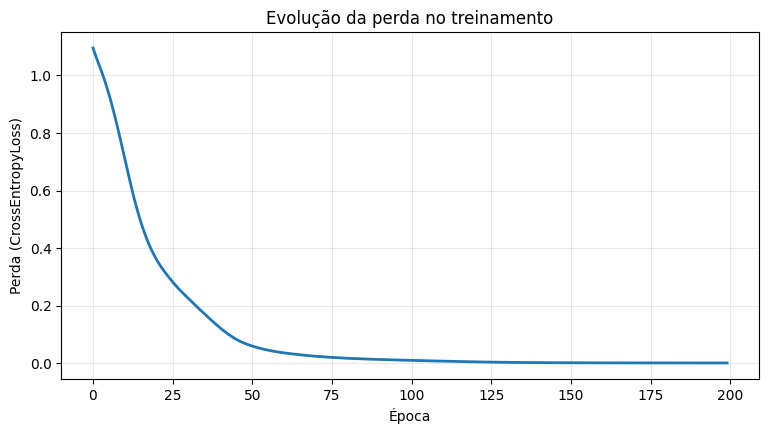

In [4]:
plt.figure(figsize=(9, 4.5))
plt.plot(range(200), hist, linewidth=2)
plt.xlabel('Época')
plt.ylabel('Perda (CrossEntropyLoss)')
plt.title('Evolução da perda no treinamento')
plt.grid(alpha=0.3)
plt.show()

### Respostas teóricas — Exercício 2

**O que aconteceria sem `zero_grad()`?** Os gradientes seriam acumulados de uma época para a outra. Com isso, as atualizações dos pesos deixariam de representar apenas a perda calculada na época atual, o que poderia atrapalhar o treinamento.

**Por que `backward()` vem depois do cálculo da perda?** Primeiro precisamos calcular a saída da rede e o valor da perda. Depois, o `backward()` usa esse resultado para calcular os gradientes que o otimizador utiliza ao atualizar os pesos.

## 4. Exercício 3 — Avaliar a rede

Na avaliação uso `eval()` e `no_grad()`, porque não precisamos calcular gradientes. Vou conferir a acurácia no treino e no teste e montar a matriz de confusão.

In [5]:
modelo.eval()
with torch.no_grad():
    pred_tr = modelo(Xtr).argmax(dim=1)
    logits_teste = modelo(Xte)
    pred_te = logits_teste.argmax(dim=1)

acuracia_treino = (pred_tr == ytr).float().mean().item()
acuracia_teste = (pred_te == yte).float().mean().item()
print(f'Acurácia de treino: {acuracia_treino:.2%}')
print(f'Acurácia de teste:  {acuracia_teste:.2%}')

Acurácia de treino: 100.00%
Acurácia de teste:  90.00%


Matriz de confusão (linhas: real | colunas: previsto):
[[ 6  0  0]
 [ 0  7  3]
 [ 0  0 14]]


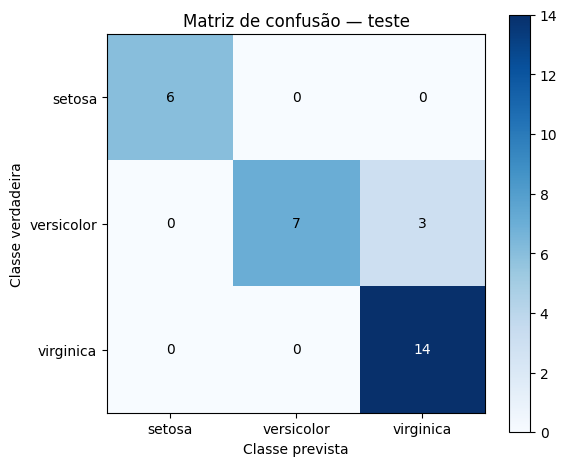

In [6]:
# Linhas = classe verdadeira; colunas = classe prevista
matriz = np.zeros((3, 3), dtype=int)
for verdadeiro, previsto in zip(yte.tolist(), pred_te.tolist()):
    matriz[verdadeiro, previsto] += 1

print('Matriz de confusão (linhas: real | colunas: previsto):')
print(matriz)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(matriz, cmap='Blues')
ax.set_xticks(range(3), labels=iris.target_names)
ax.set_yticks(range(3), labels=iris.target_names)
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe verdadeira')
ax.set_title('Matriz de confusão — teste')
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(matriz[i, j]), ha='center', va='center',
                color='white' if matriz[i, j] > matriz.max()/2 else 'black')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [7]:
# Resumo dos erros: os valores vêm da execução, não de números inventados.
print('Erros por classe:')
for i, especie in enumerate(iris.target_names):
    erros = int(matriz[i].sum() - matriz[i, i])
    print(f'- {especie}: {erros} erro(s)')

pares = [(i, j, int(matriz[i, j])) for i in range(3) for j in range(3) if i != j]
mais_confundido = max(pares, key=lambda item: item[2])
if mais_confundido[2] > 0:
    i, j, q = mais_confundido
    print(f'Maior confusão: {iris.target_names[i]} classificada como {iris.target_names[j]} ({q} vez(es)).')
else:
    print('Não houve confusões no conjunto de teste.')

Erros por classe:
- setosa: 0 erro(s)
- versicolor: 3 erro(s)
- virginica: 0 erro(s)
Maior confusão: versicolor classificada como virginica (3 vez(es)).


### Análise da matriz de confusão

A matriz mostra os acertos na diagonal principal e os erros fora dela. Em geral, **versicolor** e **virginica** podem ser confundidas porque apresentam características mais próximas entre si, enquanto **setosa** costuma ser mais fácil de separar. A contagem exata dos erros e a resposta sobre a setosa aparecem na execução acima; é importante olhar esses valores antes de concluir o resultado específico da nossa rede.

In [8]:
# Softmax transforma logits em probabilidades que somam 1.
with torch.no_grad():
    cinco_logits = modelo(Xte[:5])
    probabilidades = torch.softmax(cinco_logits, dim=1)

print('Probabilidades das 5 primeiras amostras:')
print(probabilidades)
print('Soma de cada linha:', probabilidades.sum(dim=1))
assert torch.allclose(probabilidades.sum(dim=1), torch.ones(5), atol=1e-6)

# A equivalência deve ser verificada com o mesmo lote de logits e rótulos.
perda_ce = nn.CrossEntropyLoss()(cinco_logits, yte[:5])
perda_nll = nn.NLLLoss()(torch.log_softmax(cinco_logits, dim=1), yte[:5])
print(f'CrossEntropyLoss = {perda_ce.item():.8f}')
print(f'NLLLoss(log_softmax) = {perda_nll.item():.8f}')
print('Diferença absoluta =', abs(perda_ce.item() - perda_nll.item()))
assert torch.allclose(perda_ce, perda_nll, atol=1e-6)

Probabilidades das 5 primeiras amostras:
tensor([[1.4585e-06, 1.8894e-01, 8.1106e-01],
        [2.6072e-09, 5.8678e-06, 9.9999e-01],
        [2.5858e-07, 9.4536e-03, 9.9055e-01],
        [3.7826e-06, 9.9999e-01, 3.3689e-06],
        [2.8397e-06, 9.9999e-01, 8.2387e-06]])
Soma de cada linha: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
CrossEntropyLoss = 0.33517435
NLLLoss(log_softmax) = 0.33517435
Diferença absoluta = 0.0


### Resposta — coerência do softmax

As probabilidades de cada amostra somam aproximadamente **1**, como esperado. Também verificamos que `CrossEntropyLoss(logits)` e `NLLLoss(log_softmax(logits))` produzem a mesma perda, com diferença numérica desprezível.

## 5. Desafio 1 — Comparação de otimizadores

Escolhi comparar **SGD (lr=0.01)**, **SGD com momentum (lr=0.1, momentum=0.9)** e **Adam (lr=0.01)**. Para a comparação ser justa, reinicio a mesma semente e crio uma rede nova para cada teste, mantendo a arquitetura e as 200 épocas.

In [9]:
def executar_experimento(tipo):
    torch.manual_seed(SEED)  # Mesma inicialização dos pesos em todos os testes
    rede = MLP()
    funcao_perda = nn.CrossEntropyLoss()

    if tipo == 'SGD (lr=0.01)':
        opt = torch.optim.SGD(rede.parameters(), lr=1e-2)
    elif tipo == 'SGD + momentum (lr=0.1)':
        opt = torch.optim.SGD(rede.parameters(), lr=0.1, momentum=0.9)
    else:
        opt = torch.optim.Adam(rede.parameters(), lr=1e-2)

    rede.train()
    perdas = []
    for _ in range(200):
        opt.zero_grad()
        logits = rede(Xtr)
        loss = funcao_perda(logits, ytr)
        loss.backward()
        opt.step()
        perdas.append(loss.item())

    rede.eval()
    with torch.no_grad():
        acuracia = (rede(Xte).argmax(dim=1) == yte).float().mean().item()
        perda_final = funcao_perda(rede(Xtr), ytr).item()
    return perda_final, acuracia, perdas

nomes = ['SGD (lr=0.01)', 'SGD + momentum (lr=0.1)', 'Adam (lr=0.01)']
resultados = {nome: executar_experimento(nome) for nome in nomes}

print(f'{"Otimizador":<29} | {"Perda final":>12} | {"Acurácia teste":>15}')
print('-' * 64)
for nome, (perda_final, acc, _) in resultados.items():
    print(f'{nome:<29} | {perda_final:>12.6f} | {acc:>14.2%}')

Otimizador                    |  Perda final |  Acurácia teste
----------------------------------------------------------------
SGD (lr=0.01)                 |     0.807871 |         83.33%
SGD + momentum (lr=0.1)       |     0.004499 |         90.00%
Adam (lr=0.01)                |     0.000288 |         90.00%


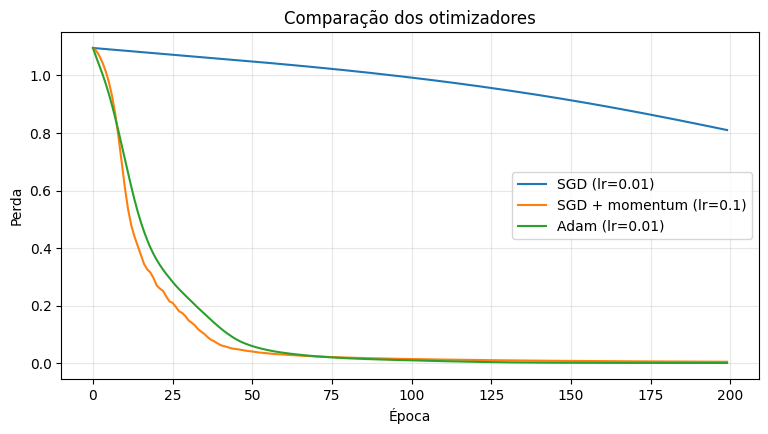

In [10]:
plt.figure(figsize=(9, 4.5))
for nome, (_, _, perdas) in resultados.items():
    plt.plot(perdas, label=nome)
plt.xlabel('Época')
plt.ylabel('Perda')
plt.title('Comparação dos otimizadores')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Resposta — Por que o SGD com `lr=0.01` fica atrás?

Com uma taxa de aprendizado pequena e sem momentum, o SGD tende a dar passos menores e avançar mais devagar durante as mesmas 200 épocas. Já o SGD com momentum acumula parte da direção das atualizações anteriores, e o Adam adapta o tamanho dos passos para cada parâmetro. Por isso, nessas condições, eles podem chegar a uma perda menor em menos épocas. A tabela acima mostra o que aconteceu no nosso experimento.

## 6. Conclusão

Nesta atividade, construí uma MLP com duas camadas ocultas, treinei o modelo com retropropagação automática e avaliei sua classificação na base Iris. A curva de perda permite acompanhar o aprendizado, e a matriz de confusão ajuda a entender os erros entre as classes. No desafio, comparei diferentes otimizadores e observei como as configurações de treinamento influenciam os resultados.

---

**Observação:** o enunciado fornece valores de referência (por exemplo, perda final abaixo de 0,001 e teste perto de 90%), mas os resultados corretos para entregar são os que aparecem ao executar este notebook. Se houver diferenças, elas devem ser relatadas, não substituídas pelos valores esperados.